# Розв'язок лінійних диференціальних рівнянь у частинних похідних у вигляді поліномів

Програмна частина кваліфікаційної роботи магістра (Муренець Н. С., ОНУ імені І. І. Мечникова, 2026).


In [77]:
%matplotlib inline
import os, sys, json, time
import numpy as np
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt


## 1. Оформлення графіків (plotstyle.py)

In [78]:
"""Оформлення графіків"""
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({'font.family': 'DejaVu Serif',
                     'font.size': 11})


def comma(v, _pos=None):
    s = f'{v:.10g}'
    return s.replace('-', '−').replace('.', ',')


def comma_axes(ax, x=True, y=True):
    if x and ax.get_xscale() == 'linear':
        ax.xaxis.set_major_formatter(FuncFormatter(comma))
    if y and ax.get_yscale() == 'linear':
        ax.yaxis.set_major_formatter(FuncFormatter(comma))

## 2. Код побудови поліноміальних розв'язків (`polysolve.py`)

Створення базисних систем kernel_basis і чотири методи розв'язання задачі Коші $u_t=u_{xx}$, $u(x,0)=\varphi(x)$ (лістинги А.1–А.3).

In [79]:
"""
Поліноміальні розв'язки лінійних ДРЧП зі сталими
коефіцієнтами: чотири методи розв'язання задачі Коші
    u_t = u_xx,   u(x, 0) = phi(x),
і генератор базисних систем поліноміальних розв'язків.
Обчислення виконуються в точній арифметиці SymPy.
"""
from itertools import product
from math import factorial

import sympy as sp

x, t, lam = sp.symbols('x t lambda')


def heat_op(u):
    """Оператор теплопровідності (d/dt - d^2/dx^2) u."""
    return sp.diff(u, t) - sp.diff(u, x, 2)


def monomials(variables, N, weights=None):
    """Мономи з ваговим степенем w1*e1+...+wd*ed <= N."""
    weights = weights or [1] * len(variables)
    ranges = [range(N // w + 1) for w in weights]
    result = []
    for exps in product(*ranges):
        deg = sum(w * e for w, e in zip(weights, exps))
        if deg <= N:
            result.append(sp.Mul(*[v**e for v, e
                                   in zip(variables, exps)]))
    return result


def kernel_basis(op, variables, N, weights=None):
    """
    Базис поліноміальних розв'язків op(u) = 0 ваговим
    степенем не вище N і матриця відповідної СЛАР.
    """
    mons = monomials(variables, N, weights)
    a = sp.symbols(f'a0:{len(mons)}')
    # загальний поліном з невідомими коефіцієнтами
    u = sum(ai * mi for ai, mi in zip(a, mons))
    # коефіцієнти op(u) при мономах -> рівняння M a = 0
    eqs = sp.Poly(sp.expand(op(u)), *variables).coeffs()
    if eqs:
        M, _ = sp.linear_eq_to_matrix(eqs, a)
    else:
        M = sp.zeros(0, len(a))
    basis = []
    for vec in M.nullspace():          
        p = sp.expand(sum(vec[i] * mons[i]
                          for i in range(len(mons))))
        
        _, P = sp.Poly(p, *variables).clear_denoms()
        basis.append(P.primitive()[1].as_expr())
    return basis, M


def method_undetermined(phi):
    """Метод невизначених коефіцієнтів, k + 2j <= deg phi."""
    N = sp.degree(phi, x)
    mons = monomials([x, t], N, weights=[1, 2])
    a = sp.symbols(f'a0:{len(mons)}')
    u = sum(ai * mi for ai, mi in zip(a, mons))
    # рівняння u_t - u_xx = 0 за всіма мономами x^k t^j
    eqs = sp.Poly(sp.expand(heat_op(u)), x, t).coeffs()
    # початкова умова u(x, 0) = phi(x)
    init = sp.expand(u.subs(t, 0) - phi)
    eqs += sp.Poly(init, x).all_coeffs()
    (values,) = sp.linsolve(eqs, a)
    return sp.expand(u.subs(dict(zip(a, values))))


def heat_polynomials(N):
    """
    v_0..v_N -- коефіцієнти розкладу e^{lam x + lam^2 t}:
    добуток відрізків рядів e^{lam x} і e^{lam^2 t}.
    """
    ex = sum(lam**p * x**p / factorial(p)
             for p in range(N + 1))
    et = sum(lam**(2*k) * t**k / factorial(k)
             for k in range(N // 2 + 1))
    G = sp.Poly(sp.expand(ex * et), lam)
    return [sp.expand(factorial(n) * G.coeff_monomial(lam**n))
            for n in range(N + 1)]


def method_generating(phi):
    """phi = sum a_n x^n  =>  u = sum a_n v_n(x, t)."""
    P = sp.Poly(phi, x)
    v = heat_polynomials(P.degree())
    return sp.expand(sum(P.coeff_monomial(x**n) * v[n]
                         for n in range(P.degree() + 1)))


def method_operator(phi, L=lambda f: sp.diff(f, x, 2)):
    """u = e^{tL} phi = sum t^j/j! L^j phi (ряд обривається)."""
    u, term, j = 0, sp.expand(phi), 0
    while term != 0:
        u += t**j / factorial(j) * term
        term = sp.expand(L(term))
        j += 1
    return sp.expand(u)


def d2_matrix(N):
    """Матриця D^2 у базисі {x^k}: A[k, k+2] = (k+1)(k+2)."""
    A = sp.zeros(N + 1, N + 1)
    for k in range(N - 1):
        A[k, k + 2] = (k + 1) * (k + 2)
    return A


def nilpotent_exp(A, s):
    """e^{sA} для нільпотентної A: скінченна сума ряду."""
    n = A.shape[0]
    S, P, j = sp.eye(n), sp.eye(n), 1
    while True:
        P = P * A * s / j            
        if P.is_zero_matrix:
            return S
        S += P
        j += 1


def method_matrix(phi):
    """c'(t) = A c(t),  c(t) = e^{tA} c(0)."""
    P = sp.Poly(phi, x)
    N = P.degree()
    c0 = sp.Matrix([P.coeff_monomial(x**k)
                    for k in range(N + 1)])
    c = nilpotent_exp(d2_matrix(N), t) * c0
    return sp.expand(sum(c[k] * x**k for k in range(N + 1)))


METHODS = {
    'невизначених коефіцієнтів': method_undetermined,
    'твірних функцій': method_generating,
    'операторний': method_operator,
    'редукції до ЗДР': method_matrix,
}

## 3. Тестова задача (2.1): $u_t=u_{xx}$, $u(x,0)=x^4-2x^2$

Функції block1 … block5 друкують розрахунок кожним методом і перевірку: підстановку в рівняння, початкову умову і різницю з аналітичним розв'язком $u=x^4-2x^2+(12x^2-4)t+12t^2$.

In [80]:
"""
Розв'язання тестової задачі (*) чотирма методами та перевірка результатів.
    u_t = u_xx,   u(x, 0) = x^4 - 2x^2.
"""
import sys
import sympy as sp

phi = x**4 - 2*x**2
exact = x**4 + 12*x**2*t + 12*t**2 - 2*x**2 - 4*t     # аналітичний розв'язок


def check(u):
    print('  Перевірка: u_t - u_xx =', sp.simplify(heat_op(u)),
          '; u(x,0) - phi =', sp.expand(u.subs(t, 0) - phi),
          '; u - u_аналіт =', sp.expand(u - exact))


def block1():
    print('Метод невизначених коефіцієнтів')
    mons = monomials([x, t], 4, weights=[1, 2])
    print('  Мономи x^k t^j, k+2j<=4:', mons)
    a = sp.symbols(f'a0:{len(mons)}')
    u = sum(ai * mi for ai, mi in zip(a, mons))
    eqs = sp.Poly(sp.expand(heat_op(u)), x, t).coeffs()
    print('  Рівняння з u_t - u_xx = 0:')
    for e in eqs:
        print('    ', e, '= 0')
    M, _ = sp.linear_eq_to_matrix(eqs, a)
    print('  Ранг матриці СЛАР:', M.rank(), ' невідомих:', len(a),
          ' вимірність ядра:', len(a) - M.rank())
    u = method_undetermined(phi)
    print('  u(x,t) =', u)
    check(u)


def block2():
    print('Метод твірних функцій')
    v = heat_polynomials(6)
    for n, p in enumerate(v):
        print(f'  v_{n}(x,t) =', p)
    u = method_generating(phi)
    print('  phi = v_4(x,0) - 2 v_2(x,0)  =>  u(x,t) =', u)
    check(u)


def block3():
    print('Операторний метод: u = sum t^j/j! D^(2j) phi')
    term, j = phi, 0
    while term != 0:
        print(f'  D^{2*j} phi =', term)
        term, j = sp.expand(sp.diff(term, x, 2)), j + 1
    print(f'  D^{2*j} phi = 0  -> ряд обривається на j = {j-1}')
    u = method_operator(phi)
    print('  u(x,t) =', u)
    check(u)


def block4():
    print('Метод редукції до системи ЗДР: c\'(t) = A c(t)')
    A = d2_matrix(4)
    print('  A =', A.tolist())
    print('  A^2 =', (A**2).tolist())
    print('  A^3 = 0:', (A**3).is_zero_matrix,
          '; власні числа A:', A.eigenvals())
    print('  e^{tA} =', nilpotent_exp(A, t).tolist())
    u = method_matrix(phi)
    print('  u(x,t) =', u)
    check(u)


def block5():
    print('Універсальний генератор: вимірність простору розв\'язків, N = 6')
    y = sp.symbols('y')
    cases = {
        'u_t - u_xx (теплопровідність)':
            (lambda u: sp.diff(u, t) - sp.diff(u, x, 2), [x, t]),
        'u_tt - u_xx (хвильове)':
            (lambda u: sp.diff(u, t, 2) - sp.diff(u, x, 2), [x, t]),
        'u_xx + u_yy (Лапласа)':
            (lambda u: sp.diff(u, x, 2) + sp.diff(u, y, 2), [x, y]),
    }
    for name, (op, vars_) in cases.items():
        basis, M = kernel_basis(op, vars_, 6)
        print(f'  {name}: dim ker = {len(basis)}')
    basis, _ = kernel_basis(cases['u_xx + u_yy (Лапласа)'][0], [x, y], 4)
    print('  Базис гармонічних поліномів степеня <= 4:')
    for p in basis:
        print('    ', p)

Функції fig_method1 … fig_method5 будують графічні частини рисунків 2.1–2.5.

In [81]:
"""
Графічні ілюстрації до методів розв'язання тестової задачі
    u_t = u_xx,   u(x, 0) = x^4 - 2x^2
(частини «б» рисунків 2.1-2.5).
"""
import numpy as np
from matplotlib.ticker import MaxNLocator
import sympy as sp

phi = x**4 - 2*x**2
exact = x**4 + 12*x**2*t + 12*t**2 - 2*x**2 - 4*t
XS = np.linspace(-1.6, 1.6, 321)


def num(expr, *args):
    return sp.lambdify(args, expr, 'numpy')


def fig_method1():
    """Рис. 2.1, б: матриця однорідної СЛАР u_t - u_xx = 0."""
    mons = monomials([x, t], 4, weights=[1, 2])
    a = sp.symbols(f'a0:{len(mons)}')
    u = sum(ai * mi for ai, mi in zip(a, mons))
    eqs = sp.Poly(sp.expand(heat_op(u)), x, t).coeffs()
    M, _ = sp.linear_eq_to_matrix(eqs, a)      
    Mf = np.array(M.tolist(), dtype=float)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    lim = np.abs(Mf).max()
    ax.imshow(Mf, cmap='RdBu_r', vmin=-lim, vmax=lim)
    for i in range(Mf.shape[0]):            
        for j in range(Mf.shape[1]):
            if Mf[i, j]:
                ax.text(j, i, f'{Mf[i, j]:g}'.replace('-', '−'),
                        ha='center', va='center', fontsize=12)
    ax.set_xticks(range(len(mons)))
    ax.set_xticklabels([f'${sp.latex(m)}$' for m in mons])
    ax.set_yticks(range(len(eqs)))
    ax.set_yticklabels([f'рівняння {i + 1}' for i in range(len(eqs))])
    ax.set_xlabel('невідомий коефіцієнт при мономі')
    ax.set_title(f'(б) Матриця СЛАР: ранг {M.rank()}, невідомих '
                 f'{len(a)}, вимірність ядра {len(a) - M.rank()}')
    fig.tight_layout()
    return fig


def fig_method5(Nmax=10):
    """Рис. 2.2, б, в: вимірності просторів розв'язків і лінії
    рівня гармонічних поліномів."""
    y = sp.Symbol('y')
    ops = [('теплопровідності', lambda u: sp.diff(u, t)
            - sp.diff(u, x, 2), [x, t], 'o', lambda N: N + 1),
           ('хвильове', lambda u: sp.diff(u, t, 2)
            - sp.diff(u, x, 2), [x, t], 's', lambda N: 2*N + 1),
           ('Лапласа', lambda u: sp.diff(u, x, 2)
            + sp.diff(u, y, 2), [x, y], '^', lambda N: 2*N + 1)]
    Ns = np.arange(1, Nmax + 1)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4.2))
    for (name, op, vs, mk, theory), off in zip(ops, (0, -0.12, 0.12)):
        dims = [len(kernel_basis(op, vs, int(N))[0]) for N in Ns]
        ax.plot(Ns + off, dims, mk, ms=7, label=f'{name} (програма)')
    ax.plot(Ns, Ns + 1, 'k-', lw=1, label='$N+1$ (наслідок 1.1)')
    ax.plot(Ns, 2*Ns + 1, 'k--', lw=1, label='$2N+1$ (теорема 1.1)')
    ax.set_xlabel('степінь N'); ax.set_ylabel('вимірність ядра')
    ax.set_title("(б) Вимірність простору розв'язків")
    ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    g = np.linspace(-1.2, 1.2, 241)
    Xg, Yg = np.meshgrid(g, g)
    re3 = Xg**3 - 3*Xg*Yg**2                   
    cs = bx.contour(Xg, Yg, re3, levels=np.linspace(-1.5, 1.5, 13),
                    cmap='RdBu_r', linewidths=1)
    bx.contour(Xg, Yg, re3, levels=[0], colors='k', linewidths=1.8)
    bx.clabel(cs, fontsize=7, fmt=lambda v: comma(round(v, 2)))
    bx.set_aspect('equal'); bx.set_xlabel('x'); bx.set_ylabel('y')
    bx.set_title('(в) Лінії рівня $x^3-3xy^2$')
    comma_axes(bx)
    fig.tight_layout()
    return fig


def fig_method2(tv=0.1):
    """Рис. 2.3, б: розв'язок як комбінація теплових поліномів."""
    v = heat_polynomials(4)
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ax.plot(XS, num(v[4], x, t)(XS, tv), '-', lw=1.8,
            label='$v_4(x,t)$')
    ax.plot(XS, num(-2*v[2], x, t)(XS, tv) + 0*XS, '--', lw=1.8,
            label='$-2v_2(x,t)$')
    ax.plot(XS, num(exact, x, t)(XS, tv), 'k-', lw=2.4,
            label='$u=v_4-2v_2$')
    ax.plot(XS, num(phi, x)(XS), ':', color='gray', lw=1.5,
            label=r'$\varphi(x)=u(x,0)$')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('x'); ax.set_ylabel('значення')
    ax.set_title(f'(б) Суперпозиція теплових поліномів, t = {comma(tv)}')
    ax.set_ylim(-2.5, 7.5); ax.grid(alpha=0.3); ax.legend()
    comma_axes(ax)
    fig.tight_layout()
    return fig


def fig_method3(tv=0.2):
    """Рис. 2.4, б: часткові суми ряду sum t^j/j! D^(2j) phi."""
    terms, term, j = [], phi, 0
    while term != 0:                     # доданки ряду, доки D^2j phi != 0
        terms.append(t**j / sp.factorial(j) * term)
        term, j = sp.expand(sp.diff(term, x, 2)), j + 1
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    S = 0
    for k, (tk, st) in enumerate(zip(terms, ['-', '--', '-.'])):
        S = S + tk
        ax.plot(XS, num(S, x, t)(XS, tv) + 0*XS, st, lw=1.8,
                label=f'$S_{k}$')
    ax.plot(XS[::16], num(exact, x, t)(XS[::16], tv), 'ko', ms=4,
            label="точний розв'язок")
    ax.set_xlabel('x'); ax.set_ylabel(f'u(x, {comma(tv)})')
    ax.set_title(f'(б) Часткові суми ряду, t = {comma(tv)}: '
                 '$S_2=u$, ряд обривається')
    ax.grid(alpha=0.3); ax.legend()
    comma_axes(ax)
    fig.tight_layout()
    return fig


def fig_method4():
    """Рис. 2.5, б: коефіцієнти c_k(t) = (e^{tA} c(0))_k."""
    A = d2_matrix(4)
    c0 = sp.Matrix([0, 0, -2, 0, 1])         
    c = nilpotent_exp(A, t) * c0
    ts = np.linspace(0, 0.5, 201)
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for k, st in zip(range(5), ['-', ':', '--', ':', '-.']):
        lab = f'$c_{k}(t)={sp.latex(sp.expand(c[k]))}$'
        ax.plot(ts, num(c[k], t)(ts) + 0*ts, st, lw=1.8, label=lab)
    ax.set_xlabel('t'); ax.set_ylabel('$c_k(t)$')
    ax.set_title(r"(б) Розв'язок системи $c'=Ac$: коефіцієнти при $x^k$")
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
    comma_axes(ax)
    fig.tight_layout()
    return fig

### 3.1. Метод невизначених коефіцієнтів (рис. 2.1)

In [82]:
block1()

Метод невизначених коефіцієнтів
  Мономи x^k t^j, k+2j<=4: [1, t, t**2, x, t*x, x**2, t*x**2, x**3, x**4]
  Рівняння з u_t - u_xx = 0:
     a6 - 12*a8 = 0
     a4 - 6*a7 = 0
     2*a2 - 2*a6 = 0
     a1 - 2*a5 = 0
  Ранг матриці СЛАР: 4  невідомих: 9  вимірність ядра: 5
  u(x,t) = 12*t**2 + 12*t*x**2 - 4*t + x**4 - 2*x**2
  Перевірка: u_t - u_xx = 0 ; u(x,0) - phi = 0 ; u - u_аналіт = 0


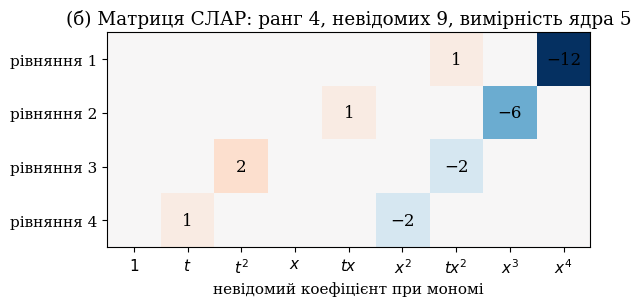

In [83]:
fig_method1()
plt.show()

### 3.2. Вимірності просторів поліноміальних розв'язків і базис гармонічних поліномів (рис. 2.2)

In [84]:
block5()

Універсальний генератор: вимірність простору розв'язків, N = 6
  u_t - u_xx (теплопровідність): dim ker = 7
  u_tt - u_xx (хвильове): dim ker = 13
  u_xx + u_yy (Лапласа): dim ker = 13
  Базис гармонічних поліномів степеня <= 4:
     1
     y
     x
     x*y
     x**2 - y**2
     3*x**2*y - y**3
     x**3 - 3*x*y**2
     x**3*y - x*y**3
     x**4 - 6*x**2*y**2 + y**4


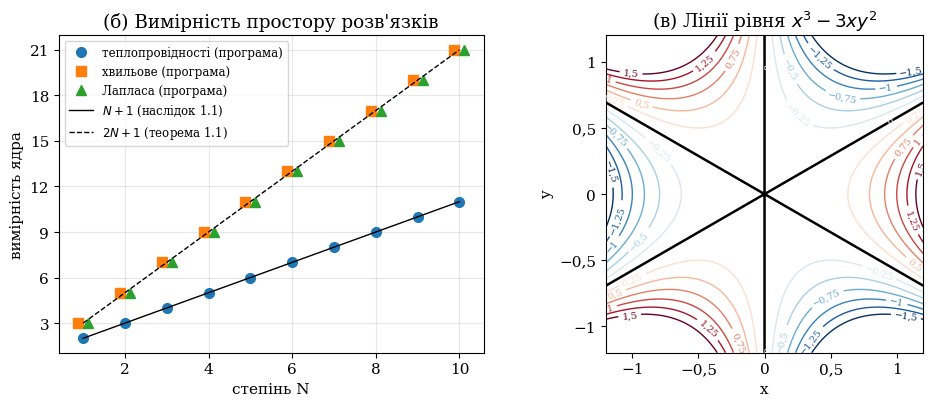

In [85]:
fig_method5()
plt.show()

### 3.3. Метод твірних функцій (рис. 2.3)

In [86]:
block2()

Метод твірних функцій
  v_0(x,t) = 1
  v_1(x,t) = x
  v_2(x,t) = 2*t + x**2
  v_3(x,t) = 6*t*x + x**3
  v_4(x,t) = 12*t**2 + 12*t*x**2 + x**4
  v_5(x,t) = 60*t**2*x + 20*t*x**3 + x**5
  v_6(x,t) = 120*t**3 + 180*t**2*x**2 + 30*t*x**4 + x**6
  phi = v_4(x,0) - 2 v_2(x,0)  =>  u(x,t) = 12*t**2 + 12*t*x**2 - 4*t + x**4 - 2*x**2
  Перевірка: u_t - u_xx = 0 ; u(x,0) - phi = 0 ; u - u_аналіт = 0


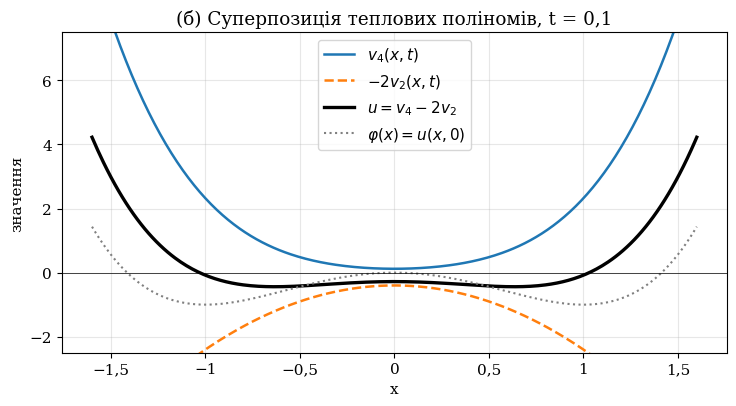

In [87]:
fig_method2()
plt.show()

### 3.4. Операторний метод (рис. 2.4)

In [88]:
block3()

Операторний метод: u = sum t^j/j! D^(2j) phi
  D^0 phi = x**4 - 2*x**2
  D^2 phi = 12*x**2 - 4
  D^4 phi = 24
  D^6 phi = 0  -> ряд обривається на j = 2
  u(x,t) = 12*t**2 + 12*t*x**2 - 4*t + x**4 - 2*x**2
  Перевірка: u_t - u_xx = 0 ; u(x,0) - phi = 0 ; u - u_аналіт = 0


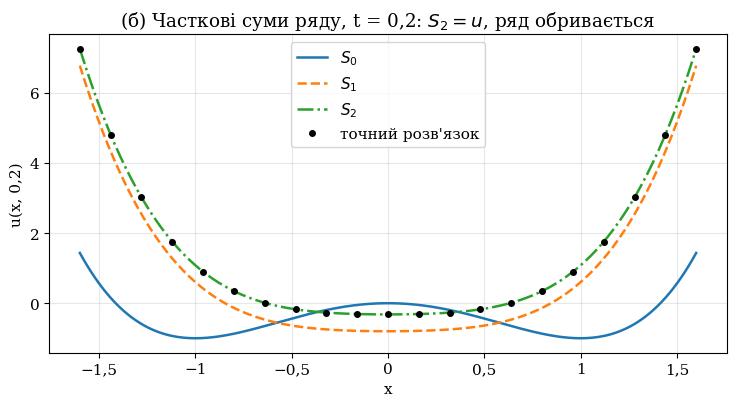

In [89]:
fig_method3()
plt.show()

### 3.5. Метод редукції до системи ЗДР (рис. 2.5)

In [90]:
block4()

Метод редукції до системи ЗДР: c'(t) = A c(t)
  A = [[0, 0, 2, 0, 0], [0, 0, 0, 6, 0], [0, 0, 0, 0, 12], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0]]
  A^2 = [[0, 0, 0, 0, 24], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0]]
  A^3 = 0: True ; власні числа A: {0: 5}
  e^{tA} = [[1, 0, 2*t, 0, 12*t**2], [0, 1, 0, 6*t, 0], [0, 0, 1, 0, 12*t], [0, 0, 0, 1, 0], [0, 0, 0, 0, 1]]
  u(x,t) = 12*t**2 + 12*t*x**2 - 4*t + x**4 - 2*x**2
  Перевірка: u_t - u_xx = 0 ; u(x,0) - phi = 0 ; u - u_аналіт = 0


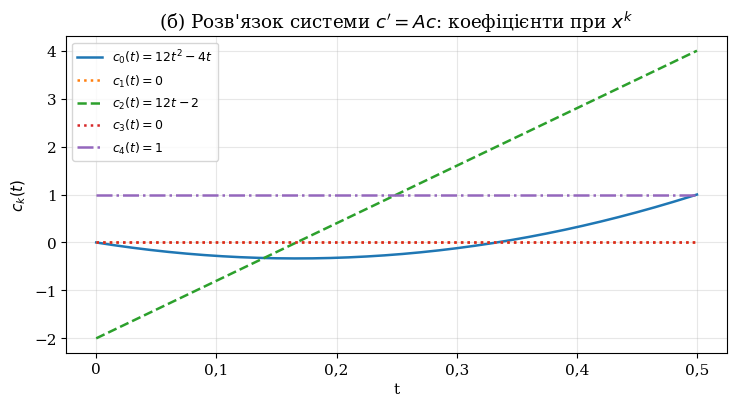

In [91]:
fig_method4()
plt.show()

### 3.6. Поверхня розв'язку задачі (2.1) та перерізи $t=\mathrm{const}$ (рис. 2.6)

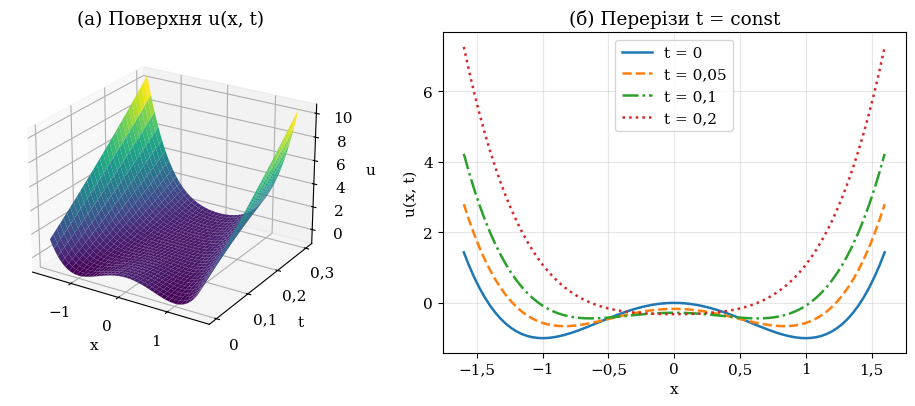

In [92]:
# u(x,t) = x^4 + 12x^2 t + 12t^2 - 2x^2 - 4t
xs = np.linspace(-1.6, 1.6, 81)
ts = np.linspace(0, 0.3, 61)
Xg, Tg = np.meshgrid(xs, ts)
U = Xg**4 + 12*Xg**2*Tg + 12*Tg**2 - 2*Xg**2 - 4*Tg
fig = plt.figure(figsize=(10, 4.2))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(Xg, Tg, U, cmap='viridis', linewidth=0)
ax.set_xlabel('x'); ax.set_ylabel('t'); ax.set_zlabel('u')
ax.set_title('(а) Поверхня u(x, t)')
ax.view_init(elev=24, azim=-58)
from matplotlib.ticker import FuncFormatter
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_formatter(FuncFormatter(comma))
ax2 = fig.add_subplot(1, 2, 2)
for tv, st in [(0, '-'), (0.05, '--'), (0.1, '-.'), (0.2, ':')]:
    ax2.plot(xs, xs**4 + 12*xs**2*tv + 12*tv**2 - 2*xs**2 - 4*tv,
             st, lw=1.8, label=f't = {comma(tv)}')
ax2.set_xlabel('x'); ax2.set_ylabel('u(x, t)')
ax2.set_title('(б) Перерізи t = const')
ax2.grid(alpha=0.3); ax2.legend()
comma_axes(ax2)
fig.tight_layout()
plt.show()

## 4. Додаткове дослідження 1: Перевірка явної різницевої схеми на точних поліноміальних розв’язках (підрозділ 2.7)

Схема $u_j^{n+1}=ru_{j-1}^n+(1-2r)u_j^n+ru_{j+1}^n$, $r=\tau/h^2$; нев'язка на розв'язку рівняння теплопровідності дорівнює $\frac{h^2}{12}(6r-1)u_{xxxx}$.

In [93]:
"""
Чисельний експеримент 1. Явна різницева схема
  u_j^{n+1} = r u_{j-1}^n + (1-2r) u_j^n + r u_{j+1}^n
на точних поліноміальних розв'язках u_t = u_xx.
Крайові значення беруться з точного розв'язку.
"""
import json
import numpy as np

V = {  
    'v2': lambda x, t: x**2 + 2*t,
    'v3': lambda x, t: x**3 + 6*x*t,
    'v4': lambda x, t: x**4 + 12*x**2*t + 12*t**2,
    'v6': lambda x, t: (x**6 + 30*x**4*t + 180*x**2*t**2
                        + 120*t**3),
    'test': lambda x, t: (x**4 + 12*x**2*t + 12*t**2
                          - 2*x**2 - 4*t),
}


def run_scheme(u_ex, h, r, T, a=-1.0, b=1.0, record=False):
    """Явна схема на [a, b]; max|u - u_ex| при t = T."""
    tau = r * h**2
    steps = int(round(T / tau))
    xs = np.linspace(a, b, int(round((b - a) / h)) + 1)
    u = u_ex(xs, 0.0)
    errors = []
    for n in range(steps):
        t1 = (n + 1) * tau
        new = np.empty_like(u)
        # внутрішні вузли: різницеве рівняння з двома індексами
        new[1:-1] = r*u[:-2] + (1 - 2*r)*u[1:-1] + r*u[2:]
        new[0], new[-1] = u_ex(xs[0], t1), u_ex(xs[-1], t1)
        u = new
        if record:
            errors.append(np.max(np.abs(u - u_ex(xs, t1))))
    err = np.max(np.abs(u - u_ex(xs, steps * tau)))
    return (err, np.array(errors)) if record else err

Таблиця 2.2 – максимальна похибка явної схеми, t = 0,1, h = 0,05
        r         v2         v3         v4     задача
   0.1667   5.33e-15   5.22e-15   5.77e-15   5.66e-15
   0.2500   7.22e-16   7.77e-16   2.47e-04   2.47e-04
   0.4000   2.22e-16   4.44e-16   6.92e-04   6.92e-04
   0.5000   2.22e-16   4.44e-16   9.89e-04   9.89e-04

Таблиця 2.3 – порядок точності, t = 0,1
        h   задача, r=0,4  відн.    v6, r=1/6  відн.
   0.1000       2.773e-03           1.318e-05       
   0.0500       6.924e-04   4.01    8.239e-07  16.00
   0.0250       1.730e-04   4.00    5.150e-08  16.00
   0.0125       4.326e-05   4.00    3.219e-09  16.00

Похибка на розв'язку v3 після 400 кроків:
  r = 0,4: 8.88e-16
  r = 0,5: 1.78e-15
  r = 0,52: 4.46e-05
  r = 0,55: 3.31e+13


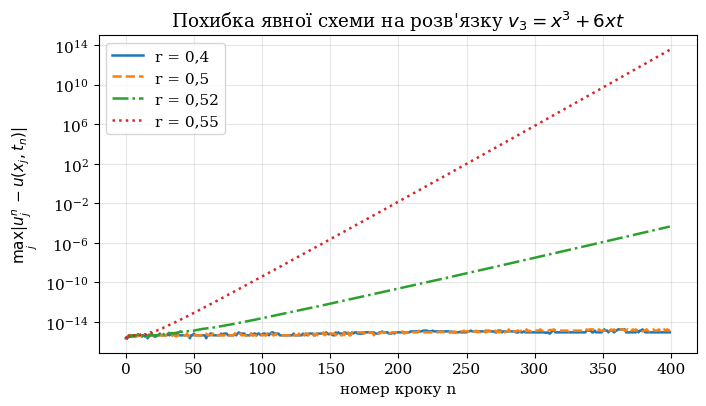

In [94]:
res = {}
h, T = 0.05, 0.1
print('Таблиця 2.2 – максимальна похибка явної схеми, '
      't = 0,1, h = 0,05')
print(f'  {"r":>7s}' + ''.join(f'{k:>11s}' for k in
                               ['v2', 'v3', 'v4', 'задача']))
res['table1'] = {}
for r in [1/6, 0.25, 0.4, 0.5]:
    row = {k: run_scheme(V[k], h, r, T)
           for k in ['v2', 'v3', 'v4', 'test']}
    res['table1'][str(r)] = row
    print(f'  {r:7.4f}' + ''.join(f'{e:11.2e}'
                                  for e in row.values()))
print('\nТаблиця 2.3 – порядок точності, t = 0,1')
print(f'  {"h":>7s}{"задача, r=0,4":>16s}{"відн.":>7s}'
      f'{"v6, r=1/6":>13s}{"відн.":>7s}')
rows = []
for h_ in [0.1, 0.05, 0.025, 0.0125]:
    rows.append([h_, run_scheme(V['test'], h_, 0.4, T),
                 run_scheme(V['v6'], h_, 1/6, T)])
    q1 = q2 = ''
    if len(rows) > 1:              
        q1 = f'{rows[-2][1] / rows[-1][1]:.2f}'
        q2 = f'{rows[-2][2] / rows[-1][2]:.2f}'
    print(f'  {h_:7.4f}{rows[-1][1]:16.3e}{q1:>7s}'
          f'{rows[-1][2]:13.3e}{q2:>7s}')
res['table2'] = rows
res['growth400'] = {}
print('\nПохибка на розв\'язку v3 після 400 кроків:')
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for r, st in [(0.4, '-'), (0.5, '--'), (0.52, '-.'),
              (0.55, ':')]:
    _, errs = run_scheme(V['v3'], 0.05, r, 400 * r * 0.05**2,
                         record=True)
    res['growth400'][str(r)] = float(errs[-1])
    print(f'  r = {comma(r)}: {errs[-1]:.2e}')
    ax.semilogy(np.maximum(errs, 1e-17), st, lw=1.8,
                label=f'r = {comma(r)}')
ax.set_xlabel('номер кроку n')
ax.set_ylabel(r'$\max_j |u_j^n - u(x_j, t_n)|$')
ax.set_title("Похибка явної схеми на розв'язку "
             r'$v_3 = x^3 + 6xt$')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


## 5. Додаткове дослідження 2: випадкове блукання і дискретні теплові поліноми (підрозділ 2.8)

$U_m(x,n)=\mathbb E(x+S_n)^m$ — поліноміальні розв'язки рівняння $u(x,n+1)=\frac12\left(u(x+1,n)+u(x-1,n)\right)$; моделюється $10^6$ блукань по $100$ кроків.

In [95]:
"""
Чисельний експеримент 2. Випадкове блукання
    u(x, n+1) = (u(x+1, n) + u(x-1, n)) / 2
і його поліноміальні розв'язки U_m(x, n) = E(x + S_n)^m.
"""
import json
from math import comb
import numpy as np
import sympy as sp

X, n_ = sp.symbols('x n')


def walk_polynomials(M):
    """
    U_0..U_M. Моменти E S_n^j -- поліноми від n степеня
    <= j/2; їх знайдено інтерполяцією за точними значеннями
    sum_k C(n,k) 2^{-n} (2k-n)^j.
    """
    def moment(j, n):
        return sum(sp.binomial(n, k) * (2*k - n)**j
                   for k in range(n + 1)) / sp.Integer(2)**n
    U = []
    for m in range(M + 1):
        mom = [sp.interpolate([(n, moment(j, n))
                               for n in range(m + 2)], n_)
               for j in range(m + 1)]
        U.append(sp.expand(sum(sp.binomial(m, j)
                               * X**(m - j) * mom[j]
                               for j in range(m + 1))))
    return U


def simulate(n_steps, n_walks, rng, chunk=200_000):
    """Положення S_n для n_walks блукань з кроком +-1."""
    out = np.empty(n_walks, dtype=np.int64)
    for s in range(0, n_walks, chunk):
        k = min(chunk, n_walks - s)
        steps = rng.integers(0, 2, size=(k, n_steps),
                             dtype=np.int8) * 2 - 1
        out[s:s + k] = steps.sum(axis=1)
    return out

U_0 = 1
U_1 = x
U_2 = n + x**2
U_3 = 3*n*x + x**3
U_4 = 3*n**2 + 6*n*x**2 - 2*n + x**4
U_5 = 15*n**2*x + 10*n*x**3 - 10*n*x + x**5
U_6 = 15*n**3 + 45*n**2*x**2 - 30*n**2 + 15*n*x**4 - 30*n*x**2 + 16*n + x**6
h^4 U_4 = 3*T**2 + 6*T*X**2 - 2*T*h**2 + X**4
h^6 U_6 = 15*T**3 + 45*T**2*X**2 - 30*T**2*h**2 + 15*T*X**4 - 30*T*X**2*h**2 + 16*T*h**4 + X**6

Таблиця 2.4 – оцінки E(x+S_n)^m, x = 1, n = 100
         N  m         оцінка          точне  відн. похибка  |Δ|/СП
      1000  2          99.28            101       1.70e-02    0.39
      1000  4        29708.5          30401       2.28e-02    0.22
      1000  6    1.51126e+07    1.51501e+07       2.48e-03    0.01
     10000  2        101.026            101       2.61e-04    0.02
     10000  4        29631.5          30401       2.53e-02    0.83
     10000  6    1.42518e+07    1.51501e+07       5.93e-02    1.03
    100000  2        100.617            101       3.79e-03    0.86
    100000  4        30031.5          30401       1.22e-02    1.2

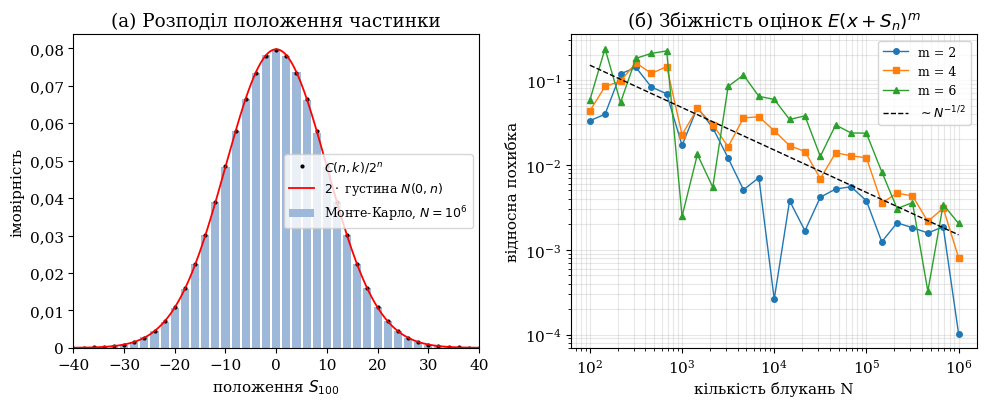

In [96]:
U = walk_polynomials(6)
for m in range(7):            # перевірка різницевого рівняння
    lhs = U[m].subs(n_, n_ + 1)
    rhs = (U[m].subs(X, X + 1) + U[m].subs(X, X - 1)) / 2
    assert sp.expand(lhs - rhs) == 0
    print(f'U_{m} =', U[m])
Xs, Ts, h = sp.symbols('X T h', positive=True)
for m in [4, 6]:              # граничний перехід
    sc = sp.expand(h**m * U[m].subs({X: Xs / h, n_: Ts / h**2},
                                     simultaneous=True))
    print(f'h^{m} U_{m} =', sc)

rng = np.random.default_rng(2026)
x0, n_steps = 1, 100
S = simulate(n_steps, 1_000_000, rng)
rows = []
print(f'\nТаблиця 2.4 – оцінки E(x+S_n)^m, x = {x0}, n = {n_steps}')
print(f'  {"N":>8s}{"m":>3s}{"оцінка":>15s}{"точне":>15s}'
      f'{"відн. похибка":>15s}{"|Δ|/СП":>8s}')
for N in [10**3, 10**4, 10**5, 10**6]:
    for m in [2, 4, 6]:
        smp = (x0 + S[:N].astype(float))**m
        est, se = smp.mean(), smp.std(ddof=1) / np.sqrt(N)
        ex = float(U[m].subs({X: x0, n_: n_steps}))
        rows.append([N, m, est, ex, abs(est - ex) / ex,
                     abs(est - ex) / se])
        print(f'  {N:8d}{m:3d}{est:15.6g}{ex:15.6g}'
              f'{rows[-1][4]:15.2e}{rows[-1][5]:8.2f}')


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ax = axes[0]
vals, counts = np.unique(S, return_counts=True)
ax.bar(vals, counts / len(S), width=1.6, color='#9db8d9',
       label=r'Монте-Карло, $N = 10^6$')
k = np.arange(0, n_steps + 1)
pk = np.array([comb(n_steps, int(i)) for i in k],
              float) / 2.0**n_steps
ax.plot(2*k - n_steps, pk, 'k.', ms=4, label=r'$C(n,k)/2^n$')
s = np.linspace(-40, 40, 400)
ax.plot(s, 2 / np.sqrt(2*np.pi*n_steps)
        * np.exp(-s**2 / (2*n_steps)), 'r-', lw=1.3,
        label=r'$2 \cdot$ густина $N(0, n)$')
ax.set_xlim(-40, 40)
ax.set_xlabel(r'положення $S_{100}$')
ax.set_ylabel('імовірність')
ax.set_title('(а) Розподіл положення частинки')
ax.legend(fontsize=9)
comma_axes(ax)
ax = axes[1]
Ns = np.unique(np.logspace(2, 6, 25).astype(int))
for m, mk in [(2, 'o'), (4, 's'), (6, '^')]:
    ex = float(U[m].subs({X: x0, n_: n_steps}))
    err = [abs(np.mean((x0 + S[:N].astype(float))**m) - ex)
           / ex for N in Ns]
    ax.loglog(Ns, err, mk + '-', ms=4, lw=1, label=f'm = {m}')
ax.loglog(Ns, 1.5 / np.sqrt(Ns), 'k--', lw=1,
          label=r'$\sim N^{-1/2}$')
ax.set_xlabel('кількість блукань N')
ax.set_ylabel('відносна похибка')
ax.set_title(r'(б) Збіжність оцінок $E(x+S_n)^m$')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Додаткове дослідження 3: поліноми високих степенів (підрозділ 2.9)

Час побудови розв'язку чотирма методами в точній арифметиці та втрата точності в арифметиці подвійної точності. Час залежить від процесора

In [97]:
"""
Чисельний експеримент 3. Поліноми високих степенів:
 (а) час побудови розв'язку чотирма методами (SymPy);
 (б) обумовленість матриць e^{D}, e^{D^2} і втрата
     точності в арифметиці подвійної точності.
"""
import json
import time
from math import comb, factorial
import numpy as np
import sympy as sp
from sympy.core.cache import clear_cache


def best_time(f, arg, repeat=3):
    """Найкращий час з repeat запусків без кешу SymPy."""
    best = float('inf')
    for _ in range(repeat):
        clear_cache()
        t0 = time.perf_counter()
        res = f(arg)
        best = min(best, time.perf_counter() - t0)
    return best, res


def heat_matrix(N, s, scaled=False):
    """
    Матриця e^{sD^2}: у базисі {x^k} елемент [k-2i, k]
    дорівнює k!/(i!(k-2i)!) s^i, у базисі {x^k/k!} -- s^i/i!.
    """
    B = np.zeros((N + 1, N + 1))
    for k in range(N + 1):
        for i in range(k // 2 + 1):
            c = 1 if scaled else (factorial(k)
                                  // factorial(k - 2*i))
            B[k - 2*i, k] = c * s**i / factorial(i)
    return B


def pascal(N):
    """Матриця Паскаля -- матриця оператора E = e^{D}."""
    return np.array([[comb(k, j) for k in range(N + 1)]
                     for j in range(N + 1)], float)


def cond_inf(B, Binv):
    return (np.linalg.norm(B, np.inf)
            * np.linalg.norm(Binv, np.inf))

Таблиця 2.5 – час побудови розв'язку, с
     N невизн.коеф.    твірні ф.  операторний  редукц. ЗДР
     4       0.0461       0.0210       0.0161       0.0072
     8       0.1753       0.0628       0.0606       0.0228
    12       0.4854       0.1290       0.1256       0.0466
    16       1.0768       0.2184       0.2145       0.0781
    20       2.0955       0.3391       0.3321       0.1201
    24       3.7024       0.4903       0.4775       0.1757
    28       6.2974       0.8039       0.6361       0.2378

Таблиця 2.6 – обумовленість і втрата точності у float64
     N   cond e^D  cond e^D2    похибка cond k! похибка k!    дані k!
     4   1.00e+02   2.25e+02   6.45e-16    6.25   4.61e-16   0.00e+00
     8   1.59e+04   1.26e+07   3.95e-13    7.34   5.89e-13   1.21e-16
    12   2.94e+06   4.31e+12   1.12e-09    7.39   1.20e-09   2.38e-16
    16   5.91e+08   4.57e+18   3.49e-06    7.39   3.05e-06   2.60e-16
    20   1.24e+11   1.18e+25   3.44e-02    7.39   3.50e-02   4.08e-16
    24   2.

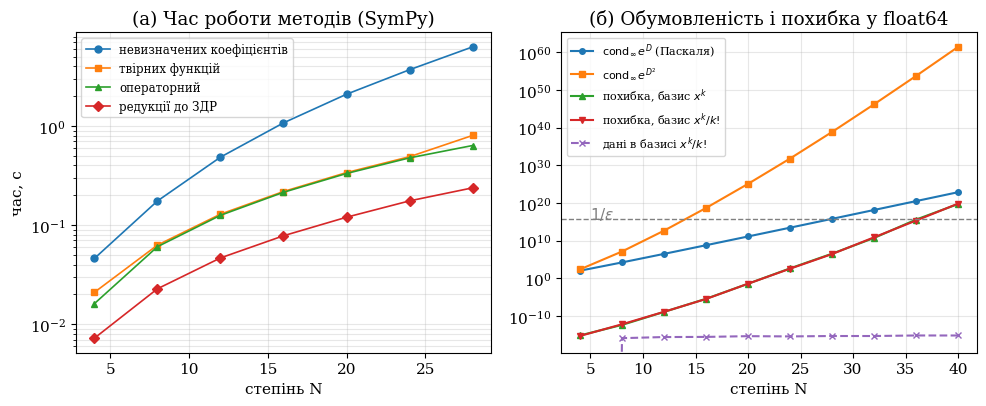

In [98]:
res = {'degrees': [4, 8, 12, 16, 20, 24, 28],
       'times': {name: [] for name in METHODS}}
print('Таблиця 2.5 – час побудови розв\'язку, с')
print(f'{"N":>6s}' + ''.join(f'{c:>13s}' for c in (
    'невизн.коеф.', 'твірні ф.', 'операторний', 'редукц. ЗДР')))
for N in res['degrees']:
    phi_N = sum(x**k for k in range(N + 1))
    out = []
    for name, f in METHODS.items():
        dt, r = best_time(f, phi_N)
        res['times'][name].append(dt)
        out.append(r)
    assert all(sp.expand(r - out[0]) == 0 for r in out)
    print(f'  {N:4d}' + ''.join(f'{res["times"][n][-1]:13.4f}'
                                for n in METHODS))

rng = np.random.default_rng(1)
rows = []
print('\nТаблиця 2.6 – обумовленість і втрата точності у float64')
print(f'{"N":>6s}' + ''.join(f'{c:>11s}' for c in (
    'cond e^D', 'cond e^D2', 'похибка')) + f'{"cond k!":>8s}'
    + ''.join(f'{c:>11s}' for c in ('похибка k!', 'дані k!')))
for N in range(4, 41, 4):
    P = pascal(N)
    H, Hi = heat_matrix(N, 1.0), heat_matrix(N, -1.0)
    Hs = heat_matrix(N, 1.0, scaled=True)
    Hsi = heat_matrix(N, -1.0, scaled=True)
    kf = np.array([float(factorial(k)) for k in range(N + 1)])
    e, es, ed = [], [], []
    for _ in range(20):
        c0 = rng.uniform(-1, 1, N + 1)
        # обернений хід e^{-D^2} e^{D^2} phi = phi
        back = Hi @ (H @ c0)
        e.append(np.max(np.abs(back - c0)) / np.max(np.abs(c0)))
        d0 = c0 * kf             # та сама phi в базисі x^k/k!
        bs = Hsi @ (Hs @ d0) / kf
        es.append(np.max(np.abs(bs - c0)) / np.max(np.abs(c0)))
        d1 = rng.uniform(-1, 1, N + 1) 
        ed.append(np.max(np.abs(Hsi @ (Hs @ d1) - d1))
                  / np.max(np.abs(d1)))
    rows.append([N, cond_inf(P, np.linalg.inv(P)),
                 cond_inf(H, Hi), float(np.median(e)),
                 cond_inf(Hs, Hsi), float(np.median(es)),
                 float(np.median(ed))])
    print(f'  {N:4d}' + ''.join(f'{v:11.2e}' for v in rows[-1][1:4])
          + f'{rows[-1][4]:8.2f}' + ''.join(f'{v:11.2e}'
                                           for v in rows[-1][5:]))
res['rows'] = rows

eps = np.finfo(float).eps
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ax = axes[0]
for (name, ts), mk in zip(res['times'].items(), 'os^D'):
    ax.semilogy(res['degrees'], ts, mk + '-', ms=5, lw=1.2,
                label=name)
ax.set_xlabel('степінь N')
ax.set_ylabel('час, с')
ax.set_title('(а) Час роботи методів (SymPy)')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8.5)
ax = axes[1]
Ns = [r[0] for r in rows]
ax.semilogy(Ns, [r[1] for r in rows], 'o-', ms=4,
            label=r'$\mathrm{cond}_\infty\, e^{D}$ (Паскаля)')
ax.semilogy(Ns, [r[2] for r in rows], 's-', ms=4,
            label=r'$\mathrm{cond}_\infty\, e^{D^2}$')
ax.semilogy(Ns, [r[3] for r in rows], '^-', ms=4,
            label=r'похибка, базис $x^k$')
ax.semilogy(Ns, [r[5] for r in rows], 'v-', ms=4,
            label=r'похибка, базис $x^k/k!$')
ax.semilogy(Ns, [r[6] for r in rows], 'x--', ms=5,
            label=r'дані в базисі $x^k/k!$')
ax.axhline(1 / eps, color='gray', ls='--', lw=1)
ax.text(5, 1.6 / eps, r'$1/\varepsilon$', color='gray')
ax.set_xlabel('степінь N')
ax.set_title('(б) Обумовленість і похибка у float64')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()